# SWYNEX Task 3 - Modeling and Evaluation: Predicting Indian Train Journey Time

**Builds on Task 1.** The input is the cleaned `trains_clean.csv` / `stations_clean.csv` produced in
*SWYNEX-Indian-Railways-Data-Preparation*, so every modelling choice below relies on data that was already audited.

## 1. Problem definition

| | |
|---|---|
| **Task** | Supervised **regression** |
| **Target** | `duration_min`: scheduled end-to-end journey time of a train, in minutes |
| **Question** | Given only what is known when a service is *planned* (distance, route, train category, zone, coaches, endpoints), how well can we predict how long the journey is scheduled to take? |
| **Why it is useful** | (1) estimate a sensible timetable for a new service, (2) **flag suspicious records**: a train whose scheduled time is far from the prediction is a candidate data error, extending the data-quality work from Task 1 |
| **Success criterion** | Beat simple, honest baselines by a clear margin on **unseen trains**, and explain where the model fails |

**Approach:** start with simple baselines, add models one step at a time, compare them with cross-validation,
and touch the test set only once at the end.

## How Tasks 1 and 2 feed this task

| Earlier finding | How it is used here |
|---|---|
| Task 2, insight 1: distance is right-skewed, use `log(distance)` | The target is modelled on a log scale, and one linear model uses `log(distance)` |
| Task 2, insight 2: never use duration to predict speed (leakage) | Same rule applied in reverse: no speed, arrival or overnight columns are used to predict duration |
| Task 2, insight 3: train type drives speed, zone is secondary | Tested **out of sample** in the ablation (Task 2 reported in-sample R2 and said so in its limitations) |
| Task 2, insight 4: speed rises with distance but saturates | Needs a non-linear model; this is what the linear vs tree comparison checks |
| Task 2, insight 6: unknown zone is informative | `Unknown` is kept as its own category, not dropped or imputed; its error is checked separately |
| Task 1: quality flags (`distance_geo_mismatch`, `speed_suspect`) | `speed_suspect` rows are excluded from training; `distance_geo_mismatch` is used to check whether big model misses are really data errors |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

warnings.filterwarnings("ignore")
SEED = 42
REPORT_DIR = Path("reports"); REPORT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load the cleaned data and attach station coordinates

`keep_default_na=False, na_values=[""]` is the habit from Task 1: it protects the real station code `NAN`
from being read as a missing value.

Origin and destination **latitude/longitude** are joined from the stations table.

In [2]:
trains = pd.read_csv("data/processed/trains_clean.csv", keep_default_na=False, na_values=[""])
stations = pd.read_csv("data/processed/stations_clean.csv", keep_default_na=False, na_values=[""])

coords = stations.set_index("code")[["lat", "lon"]]
for p, col in (("origin", "from_station_code"), ("dest", "to_station_code")):
    trains[f"{p}_lat"] = trains[col].map(coords["lat"])
    trains[f"{p}_lon"] = trains[col].map(coords["lon"])

print("Trains loaded:", trains.shape)
print("Share of trains missing origin/destination coordinates: "
      f"{trains[['origin_lat', 'dest_lat']].isna().any(axis=1).mean():.1%}")
trains[["train_no", "train_type", "zone", "distance_km", "duration_min", "route_points"]].head()

Trains loaded: (5193, 44)
Share of trains missing origin/destination coordinates: 0.6%


,train_no,train_type,zone,distance_km,duration_min,route_points
0,1101,Express,CR,1216.0,1425.0,151
1,1102,Express,CR,1216.0,1265.0,151
2,1493,Express,CR,249.0,355.0,33
3,1494,Express,CR,249.0,365.0,33
4,2081,Express,NWR,229.0,395.0,25


## 3. Choose the modelling table (and avoid leakage)

**Rows used.** Trains with a distance and a duration that were **not** flagged `speed_suspect` in Task 1
(3 rows with speeds of 8 to 540 km/h). Training on records already known to be wrong would teach the model noise.
The 27 zero-distance rows (nulled in Task 1) are excluded too.

**Leakage check.** Several columns in the cleaned table are *derived from the target* or encode it. Using them
would give a spectacular but meaningless score:

| Column | Why it is excluded |
|---|---|
| `avg_speed_kmph` | = distance / duration, contains the target |
| `arrival_min`, `arrival_time` | `arrival - departure` equals duration (the Task 1 clock check passed for every train) |
| `days_en_route`, `is_overnight` | computed from duration |
| `distance_geo_mismatch`, `geo_ratio`, `speed_suspect` | quality flags built from distance or speed |
| `train_id`, `name`, station names, `return_train_no` | identifiers / free text (the return train is used only for grouping, next section) |

**Features kept** (all known at planning time): `distance_km`, `route_km_geo` (length of the drawn route),
`n_classes` and six class flags, `departure_min`, `is_slip_coach`, origin/destination coordinates,
and the categoricals `train_type` and `zone`.

In [3]:
NUM = ["distance_km", "route_km_geo", "departure_min", "n_classes",
       "origin_lat", "origin_lon", "dest_lat", "dest_lon"]
BOOL = ["first_ac", "second_ac", "third_ac", "sleeper", "chair_car", "first_class", "is_slip_coach"]
CAT = ["train_type", "zone"]
TARGET = "duration_min"

df = trains[trains["distance_km"].notna() & trains[TARGET].notna() & ~trains["speed_suspect"]].copy()
df[BOOL] = df[BOOL].astype(int)
print(f"Modelling rows: {len(df)} of {len(trains)}  (dropped {len(trains) - len(df)} unusable / suspect rows)")
print("\nTarget summary (minutes):")
print(df[TARGET].describe().round(0).to_string())

Modelling rows: 5163 of 5193  (dropped 30 unusable / suspect rows)

Target summary (minutes):
count    5163.0
mean      678.0
std       761.0
min        10.0
25%       160.0
50%       365.0
75%       910.0
max      5130.0


## 4. Look at the target

Journey times are strongly **right-skewed** (many short passenger trains, a few multi-day expresses). Two consequences:
models are trained on `log(duration)` so relative errors matter equally for short and long trains, and I report
**percentage errors** next to minute errors, because "off by 60 minutes" means very different things on a 90-minute and a
30-hour journey.

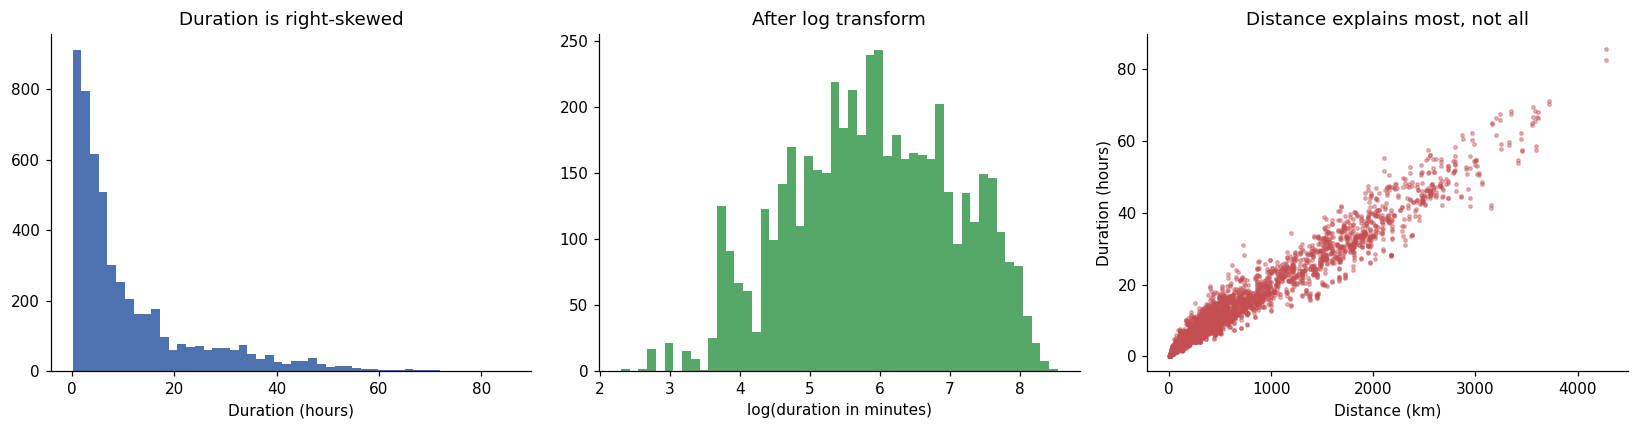

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df[TARGET] / 60, bins=50, color="#4C72B0"); ax[0].set_xlabel("Duration (hours)"); ax[0].set_title("Duration is right-skewed")
ax[1].hist(np.log(df[TARGET]), bins=50, color="#55A868"); ax[1].set_xlabel("log(duration in minutes)"); ax[1].set_title("After log transform")
ax[2].scatter(df["distance_km"], df[TARGET] / 60, s=5, alpha=.4, color="#C44E52")
ax[2].set_xlabel("Distance (km)"); ax[2].set_ylabel("Duration (hours)"); ax[2].set_title("Distance explains most, not all")
plt.tight_layout(); plt.savefig(REPORT_DIR / "target_distribution.png", dpi=150); plt.show()

## 5. A train / test split that does not cheat

A plain random split would be **optimistic**: the data contains near-duplicates. A train and its **return train**
run the same route in opposite directions with almost identical times, and slip coaches share a base train number.
If one twin is in training and the other in test, the model is "tested" on something it effectively memorised.

So I build a **group id** (a train and its return train share one id) and split by group. All cross-validation uses
`GroupKFold` for the same reason. The test set (20% of groups) is not touched until the final model is chosen.

In [5]:
base_no = df["train_no"].astype(int)
ret_no = df["return_train_no"]
df["group"] = np.where(ret_no.notna(), np.minimum(base_no, ret_no.fillna(0).astype(int)), base_no)
print("Rows:", len(df), "| independent route groups:", df["group"].nunique())

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df["group"]))
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
assert set(train["group"]).isdisjoint(test["group"]), "group leakage between train and test"
print(f"Train: {len(train)} rows | Test: {len(test)} rows | no group appears in both")

FEATURES = NUM + BOOL + CAT
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

Rows: 5163 | independent route groups: 3102
Train: 4101 rows | Test: 1062 rows | no group appears in both


## 6. Metrics: what "good" means here

| Metric | Why it is used |
|---|---|
| **MAE** (minutes) | Average miss, directly interpretable |
| **RMSE** (minutes) | Punishes big misses; the gap between RMSE and MAE shows how heavy the error tail is |
| **R2** | Share of variance explained. Dominated by long journeys, so never read alone |
| **Median abs. % error (MdAPE)** | Typical *relative* miss, fair to short and long trains |
| **Within 15%** | Share of trains predicted within +/-15% of the scheduled time, an easy-to-explain reliability number |

In [6]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ape = np.abs(y_true - y_pred) / y_true
    return {"MAE (min)": mean_absolute_error(y_true, y_pred),
            "RMSE (min)": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred),
            "MdAPE (%)": np.median(ape) * 100,
            "Within 15% (%)": (ape <= 0.15).mean() * 100}

## 7. Baselines

A model only means something relative to something simple. Three baselines, each adding one idea:

1. **Median duration**: ignores everything (the floor).
2. **Distance / global median speed**: time = distance / speed, one speed for all trains.
3. **Distance / median speed *of that train type***: a Rajdhani and a Passenger no longer share a speed.

Baseline 3 is deliberately strong: it is what a knowledgeable person would do by hand. The ML models must beat *it*,
not just the median.

In [7]:
class SpeedBaseline:
    """duration = distance / median speed (optionally per group of trains)."""
    def __init__(self, by=None): self.by = by
    def fit(self, X, y):
        speed = X["distance_km"] / (y / 60)
        self.global_speed_ = speed.median()
        if self.by: self.speed_ = speed.groupby(X[self.by]).median()
        return self
    def predict(self, X):
        sp = X[self.by].map(self.speed_).fillna(self.global_speed_) if self.by else self.global_speed_
        return (X["distance_km"] / sp * 60).to_numpy()

baselines = {
    "Baseline 1: median duration": DummyRegressor(strategy="median"),
    "Baseline 2: distance / global speed": SpeedBaseline(),
    "Baseline 3: distance / speed per type": SpeedBaseline(by="train_type"),
}

## 8. Models

Preprocessing sits inside a scikit-learn `Pipeline`, so it is fitted **only on training folds** (no leakage from
imputation or encoding):

- numeric: median imputation (only the coordinates have a few missing values)
- categorical (`train_type`, `zone`): one-hot, unseen categories ignored
- target: `log(duration)` for the log-log linear model and both tree models (predictions converted back to minutes); the two plain linear models use raw minutes, because a straight line on `log(duration)` against raw distance would imply exponential growth and explode on long trains

| Model | Idea |
|---|---|
| Linear regression (distance only) | Straight-line time vs distance, ignores everything else |
| Linear regression (log distance) | Task 2's recommendation: a straight line on the log-log scale (a power law) |
| Linear regression (all features) | Does adding train type, zone and so on help a linear model? |
| Random forest | Many decision trees; captures interactions (e.g. type x distance) |
| Gradient boosting (HistGB) | Trees built sequentially to correct errors; usually strongest on tabular data |

In [8]:
def make_pre(num=NUM + BOOL, cat=CAT):
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])

def log_target(est):
    return TransformedTargetRegressor(regressor=est, func=np.log, inverse_func=np.exp)

models = {
    # plain linear models use raw minutes: a line on log(duration) vs raw distance would imply exponential growth
    "Linear (distance only)": Pipeline([
        ("pre", ColumnTransformer([("d", "passthrough", ["distance_km"])])), ("m", LinearRegression())]),
    "Linear (log distance, Task 2)": log_target(Pipeline([
        ("pre", ColumnTransformer([("d", FunctionTransformer(np.log), ["distance_km"])])), ("m", LinearRegression())])),
    "Linear (all features)": Pipeline([("pre", make_pre()), ("m", LinearRegression())]),
    "Random forest": log_target(Pipeline([("pre", make_pre()),
        ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED))])),
    "Gradient boosting": log_target(Pipeline([("pre", make_pre()),
        ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=SEED))])),
}

## 9. Compare everything with grouped 5-fold cross-validation (training set only)

Every candidate, baselines included, is scored on the same five group-respecting folds. Mean +/- standard deviation
across folds shows both accuracy and stability. The test set is not used here.

In [9]:
gkf = GroupKFold(n_splits=5)
groups_train = train["group"]

def fresh(model):
    return SpeedBaseline(model.by) if isinstance(model, SpeedBaseline) else clone(model)

def cv_table(named_models):
    res = {}
    for name, model in named_models.items():
        folds = []
        for fit_i, val_i in gkf.split(X_train, y_train, groups_train):
            m = fresh(model).fit(X_train.iloc[fit_i], y_train.iloc[fit_i])
            folds.append(evaluate(y_train.iloc[val_i], m.predict(X_train.iloc[val_i])))
        f = pd.DataFrame(folds)
        res[name] = {k: (f"{f[k].mean():.3f} +/- {f[k].std():.3f}" if k == "R2"
                         else f"{f[k].mean():.1f} +/- {f[k].std():.1f}") for k in f}
        res[name]["_mae"] = f["MAE (min)"].mean()
    return pd.DataFrame(res).T

cv_results = cv_table({**baselines, **models}).sort_values("_mae", ascending=False)
cv_results.drop(columns="_mae")

,MAE (min),RMSE (min),R2,MdAPE (%),Within 15% (%)
Baseline 1: median duration,499.2 +/- 29.1,812.4 +/- 52.4,-0.168 +/- 0.014,71.7 +/- 1.7,10.3 +/- 1.8
Baseline 2: distance / global speed,197.3 +/- 10.8,356.1 +/- 19.9,0.775 +/- 0.007,22.6 +/- 0.8,33.9 +/- 1.8
Linear (distance only),103.4 +/- 2.6,153.4 +/- 8.0,0.958 +/- 0.005,17.8 +/- 0.6,43.6 +/- 1.4
"Linear (log distance, Task 2)",97.0 +/- 4.0,156.6 +/- 8.4,0.956 +/- 0.004,14.4 +/- 0.2,51.6 +/- 0.4
Linear (all features),76.4 +/- 3.5,109.7 +/- 7.1,0.979 +/- 0.003,13.6 +/- 0.3,53.7 +/- 1.2
Baseline 3: distance / speed per type,63.3 +/- 4.1,104.4 +/- 8.6,0.981 +/- 0.001,10.3 +/- 0.6,63.4 +/- 2.3
Random forest,54.7 +/- 3.8,98.1 +/- 15.6,0.983 +/- 0.006,7.1 +/- 0.5,76.5 +/- 1.2
Gradient boosting,53.1 +/- 3.6,91.9 +/- 11.4,0.985 +/- 0.004,7.3 +/- 0.4,76.8 +/- 1.2


**Reading the cross-validation table** (lower MAE / MdAPE is better)

- **The ladder is clear.** Typical error falls from 499 min (median) to 197 (one global speed), to 103 (straight line on distance),
  to 63 (a speed per train type), to about 53 for the tree models. Every step of added information helps.
- **Task 2's `log(distance)` advice holds up.** The log-log linear model beats the plain straight line on relative error
  (MdAPE 14.4% vs 17.8%), consistent with Task 2 insight 4: speed rises with distance but saturates.
- **Train type matters more than the functional form.** The hand-made "speed per type" rule (MdAPE 10.3%) beats both of those
  distance-only linear models, and even beats a linear model fed *all* features (13.6%). A linear model adds effects, but speed
  works multiplicatively (type x distance x region), which is why the rule does better.
- **Trees beat the strongest baseline.** Random forest and gradient boosting reach MdAPE of about 7.1-7.3% against 10.3% for
  Baseline 3, and put 77% of trains within 15% of the scheduled time against 63%. Fold-to-fold standard deviations are small
  compared with these gaps, so the ranking is not an accident of one split.
- Random forest and gradient boosting are nearly tied; gradient boosting has the lower MAE and RMSE, so I tune that one.

Next, a small hyper-parameter search, still inside the training set only.

In [10]:
param_grid = {
    "regressor__m__learning_rate": [0.03, 0.06],
    "regressor__m__max_leaf_nodes": [15, 31],
    "regressor__m__min_samples_leaf": [10, 30],
    "regressor__m__max_iter": [300, 600],
}
gs = GridSearchCV(models["Gradient boosting"], param_grid, cv=gkf, scoring="neg_mean_absolute_error", n_jobs=-1)
gs.fit(X_train, y_train, groups=groups_train)
print("Best params :", {k.split("__")[-1]: v for k, v in gs.best_params_.items()})
print(f"CV MAE      : {-gs.best_score_:.1f} min  (default settings: {cv_results.loc['Gradient boosting', '_mae']:.1f} min)")
best_model = gs.best_estimator_

Best params : {'learning_rate': 0.06, 'max_iter': 600, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}
CV MAE      : 52.2 min  (default settings: 53.1 min)


## 10. Final evaluation on the held-out test set

Models are refit on the full training set and scored **once** on 20% of route groups they have never seen.

In [11]:
final = {}
for name, m in baselines.items():
    final[name] = evaluate(y_test, fresh(m).fit(X_train, y_train).predict(X_test))
for name, m in models.items():
    final[name] = evaluate(y_test, fresh(m).fit(X_train, y_train).predict(X_test))
final["Gradient boosting (tuned)"] = evaluate(y_test, best_model.predict(X_test))

test_table = pd.DataFrame(final).T.sort_values("MAE (min)", ascending=False)
test_table.round(2).to_csv(REPORT_DIR / "test_metrics.csv")
test_table.round(2)

,MAE (min),RMSE (min),R2,MdAPE (%),Within 15% (%)
Baseline 1: median duration,532.30,863.09,-0.20,71.43,12.43
Baseline 2: distance / global speed,227.32,397.68,0.75,24.44,31.83
Linear (distance only),111.92,167.41,0.95,18.60,42.84
"Linear (log distance, Task 2)",104.59,169.41,0.95,15.14,49.15
Linear (all features),87.57,129.64,0.97,14.63,50.66
Baseline 3: distance / speed per type,74.12,125.70,0.97,10.17,63.37
Random forest,64.09,112.95,0.98,7.71,74.76
Gradient boosting,60.06,106.73,0.98,7.34,75.42
Gradient boosting (tuned),59.69,107.42,0.98,6.98,77.31


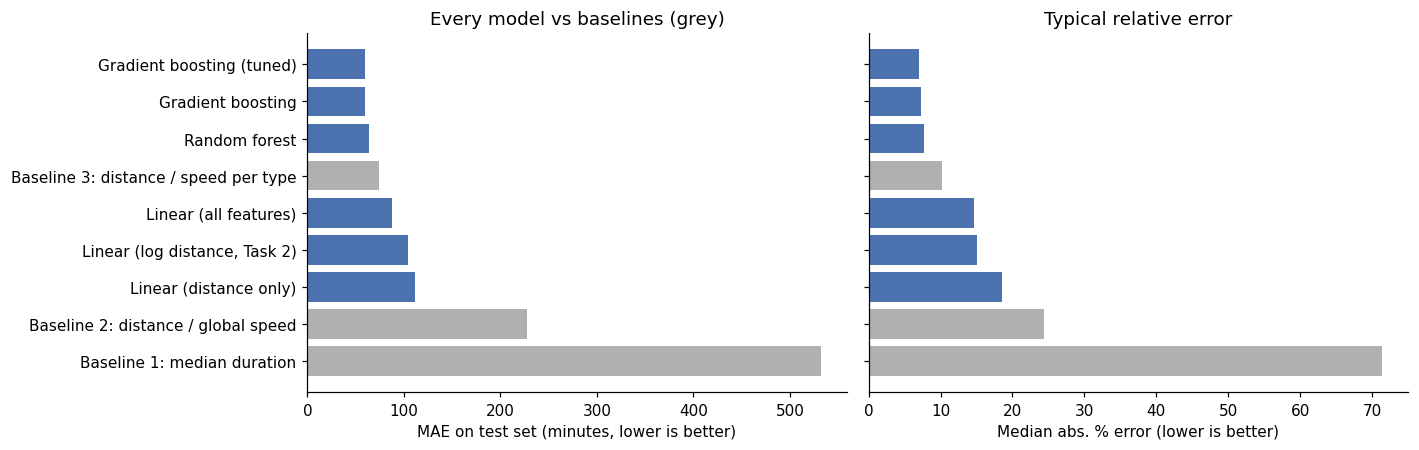

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
order = test_table.index
colors = ["#B0B0B0" if n.startswith("Baseline") else "#4C72B0" for n in order]
ax[0].barh(order, test_table["MAE (min)"], color=colors); ax[0].set_xlabel("MAE on test set (minutes, lower is better)")
ax[0].set_title("Every model vs baselines (grey)")
ax[1].barh(order, test_table["MdAPE (%)"], color=colors); ax[1].set_xlabel("Median abs. % error (lower is better)")
ax[1].set_title("Typical relative error"); ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(REPORT_DIR / "model_comparison.png", dpi=150); plt.show()

**Test-set result.** The tuned gradient boosting model reaches an MAE of **59.7 min** and a median error of **7.0%**, with
**77%** of unseen trains predicted within 15%. Against the strongest hand-made baseline (speed per type: 74.1 min, 10.2%, 63%),
that is about **19% lower MAE**, **31% lower median % error**, and 14 more percentage points of trains within 15%.

Two honest caveats:

- **R2 (0.98) flatters the model.** The speed-per-type rule already scores 0.97, because R2 is dominated by long journeys.
  The relative-error metrics show the real improvement.
- **Tuning barely mattered.** Cross-validated MAE moved from 53.1 to 52.2 min, so the gap between default and tuned models on the
  test set is within noise. The test MAE (59.7) is higher than the cross-validated figure (about 52) because the test set is a
  different, single sample of 1,062 trains; one split is a noisier estimate than the five-fold average.

## 11. Where is the model right and wrong?

A single average hides structure. I look at (a) predicted vs actual, (b) error by distance band and (c) error by train type.

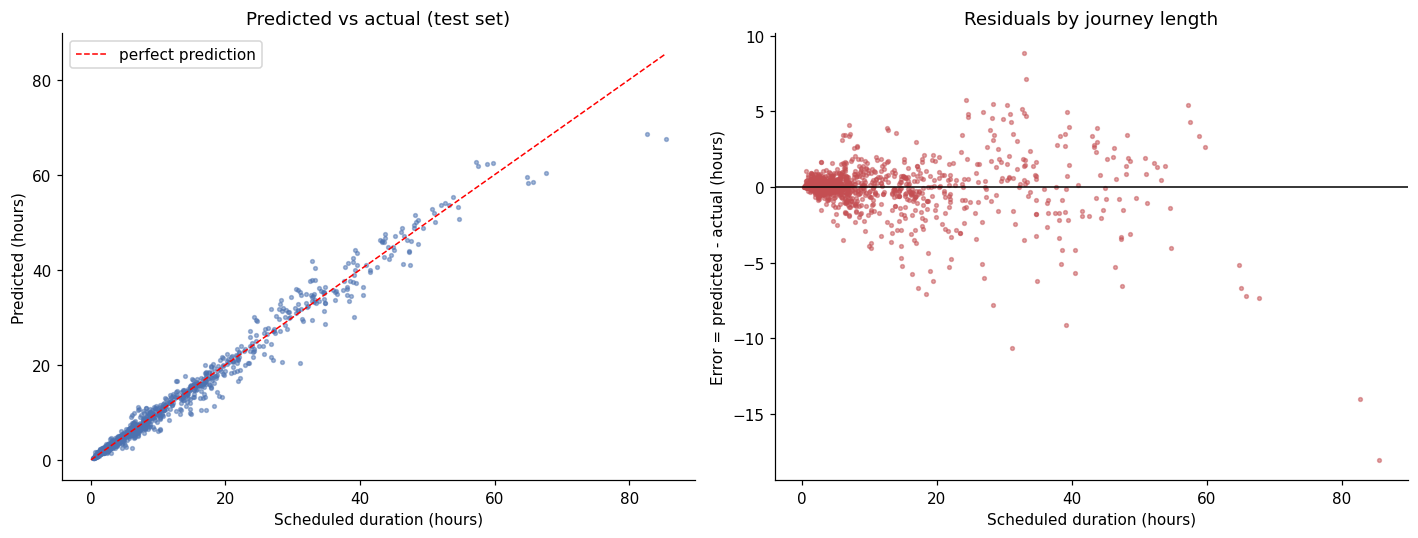

In [13]:
pred = best_model.predict(X_test)
res = test.assign(pred=pred, err=pred - y_test, abs_err=np.abs(pred - y_test), ape=np.abs(pred - y_test) / y_test * 100)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test / 60, pred / 60, s=6, alpha=.5, color="#4C72B0")
lim = max(y_test.max(), pred.max()) / 60
ax[0].plot([0, lim], [0, lim], "r--", lw=1, label="perfect prediction"); ax[0].legend()
ax[0].set_xlabel("Scheduled duration (hours)"); ax[0].set_ylabel("Predicted (hours)"); ax[0].set_title("Predicted vs actual (test set)")
ax[1].scatter(y_test / 60, res["err"] / 60, s=6, alpha=.5, color="#C44E52")
ax[1].axhline(0, color="k", lw=1); ax[1].set_xlabel("Scheduled duration (hours)"); ax[1].set_ylabel("Error = predicted - actual (hours)")
ax[1].set_title("Residuals by journey length")
plt.tight_layout(); plt.savefig(REPORT_DIR / "predicted_vs_actual.png", dpi=150); plt.show()

In [14]:
res["distance_band"] = pd.cut(res["distance_km"], [0, 100, 300, 700, 1500, 5000],
                              labels=["<100 km", "100-300", "300-700", "700-1500", ">1500 km"])
by_band = res.groupby("distance_band", observed=True).agg(
    trains=("ape", "size"), MAE_min=("abs_err", "mean"), MdAPE_pct=("ape", "median"),
    within_15pct=("ape", lambda s: (s <= 15).mean() * 100)).round(1)
display(by_band)

by_type = res.groupby("train_type", observed=True).agg(
    trains=("ape", "size"), MAE_min=("abs_err", "mean"), MdAPE_pct=("ape", "median")).round(1)
display(by_type[by_type.trains >= 8].sort_values("MdAPE_pct"))

,trains,MAE_min,MdAPE_pct,within_15pct
distance_band,,,,
<100 km,290,14.2,8.5,70.7
100-300,270,37.4,9.2,71.5
300-700,219,70.4,7.6,75.8
700-1500,136,81.2,4.2,91.2
>1500 km,147,154.4,5.0,90.5


,trains,MAE_min,MdAPE_pct
train_type,,,
Rajdhani,15,72.6,2.6
MEMU (electric multiple unit),47,8.6,3.4
Superfast,180,65.2,4.1
Hyd,20,3.9,5.2
Express,248,102.5,7.2
Shatabdi,12,26.5,7.8
Jan Shatabdi,16,49.6,8.8
Passenger,486,41.7,9.9
Garib Rath,12,187.9,12.7


**Findings**

- **Absolute error grows with distance, relative error falls.** MAE rises from 14 min (< 100 km) to 154 min (> 1,500 km),
  but the median percentage error drops from about 8.5-9% on trips under 300 km to 4-5% above 700 km. About 70% of short
  trains fall within 15%, versus about 90% of long ones. Long journeys are *more* predictable in proportion, likely because they
  run at steadier average speeds; short ones are more sensitive to local conditions the data does not contain.
- **Premium and electric multiple-unit services are the easiest:** Rajdhani 2.6%, MEMU 3.4%, Superfast 4.1% median error.
- **Passenger trains (9.9%) and Garib Rath (12.7%) are hardest.** Garib Rath has only 12 test trains but a large MAE (188 min),
  so it is a place to look first. Types with fewer than 8 test trains are omitted, and the small ones are noisy.
- The residual plot shows the spread widening with duration, as expected for a model that errs proportionally. It also shows a
  **systematic weakness at the extreme end**: the few journeys longer than about 60 hours are all under-predicted. Tree models
  cannot extrapolate beyond what they have seen, and there are very few such trains to learn from.

## 12. What drives the predictions? (permutation importance)

Permutation importance shuffles one feature at a time on the **test** set and measures how much the error grows.
A feature that matters causes a large increase; one the model ignores causes almost none.

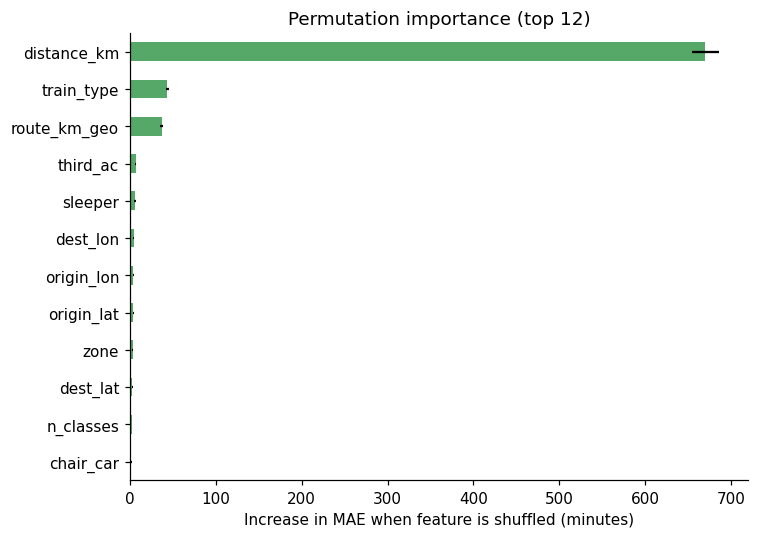

distance_km     669.7
train_type       43.8
route_km_geo     37.1
third_ac          7.1
sleeper           5.7
dest_lon          4.3
dtype: float64

In [15]:
perm = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
std = pd.Series(perm.importances_std, index=FEATURES)
fig, ax = plt.subplots(figsize=(7, 5))
top = imp.tail(12)
top.plot.barh(ax=ax, xerr=std[top.index], color="#55A868")
ax.set_xlabel("Increase in MAE when feature is shuffled (minutes)"); ax.set_title("Permutation importance (top 12)")
plt.tight_layout(); plt.savefig(REPORT_DIR / "feature_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).head(6).round(1)

**Reading it:** distance dominates (shuffling it raises MAE by about 670 min), followed by `train_type` (+44 min) and
`route_km_geo` (+37 min). The coach-class flags and destination longitude add less than 8 min each.

Caution: `distance_km` and `route_km_geo` are highly correlated (Task 2 found Spearman 0.92 to 0.99), so permutation importance
splits their credit and understates both. This ranking says what the model *uses*, not what *causes* longer journeys.

## 13. Do the extra features earn their place? (ablation)

An honest check: if the model with only `distance_km` and `train_type` is nearly as good, the rest is complexity without benefit.
Each row below adds features to the previous one (gradient boosting, same split).

In [16]:
def fit_eval(num, bool_, cat):
    cols = num + bool_ + cat
    pipe = log_target(Pipeline([("pre", make_pre(num + bool_, cat)),
        ("m", HistGradientBoostingRegressor(learning_rate=0.06, max_iter=300, random_state=SEED))]))
    pipe.fit(X_train[cols], y_train)
    return evaluate(y_test, pipe.predict(X_test[cols]))

geo = ["distance_km", "route_km_geo", "origin_lat", "origin_lon", "dest_lat", "dest_lon"]
ablation = pd.DataFrame({
    "distance only":                  fit_eval(["distance_km"], [], []),
    "+ train type":                   fit_eval(["distance_km"], [], ["train_type"]),
    "+ zone":                         fit_eval(["distance_km"], [], ["train_type", "zone"]),
    "+ coordinates & route geometry": fit_eval(geo, [], ["train_type", "zone"]),
    "+ coaches, departure (all)":     fit_eval(NUM, BOOL, CAT),
}).T
ablation.round(2)

,MAE (min),RMSE (min),R2,MdAPE (%),Within 15% (%)
distance only,103.74,173.82,0.95,14.55,51.22
+ train type,72.25,127.52,0.97,9.62,63.65
+ zone,67.25,119.78,0.98,8.65,68.74
+ coordinates & route geometry,60.32,108.72,0.98,6.96,75.71
"+ coaches, departure (all)",60.55,108.05,0.98,7.35,75.89


**Task 2's claim, tested out of sample.** Adding train type to distance cuts MAE from 103.7 to 72.3 min (a 31-minute gain).
Adding zone on top gives a further 5 minutes (to 67.3). So **type matters several times more than zone**, which confirms Task 2
insight 3 on held-out data. Task 2 had reported this from in-sample R2 and flagged that limitation; here it holds up.

Coordinates and route geometry give another 7 minutes (to 60.3), plausibly acting as a proxy for region and terrain. The final block
(coach flags, departure time, slip-coach flag) adds **nothing** (60.6 min vs 60.3, within noise), so a simpler model without them
would be just as good. They are kept in the final model for completeness; dropping them is a sensible simplification.

These are single-split numbers, so differences of one or two minutes should not be over-read.

## 14. Do Task 1 and Task 2 findings show up in the errors?

Two checks: (a) Task 2 said missing `zone` is informative (mostly short local trains), so how does the model do on
`Unknown`-zone trains? (b) Are the largest misses concentrated in trains Task 1 flagged with a **distance / route-geometry mismatch**?

In [17]:
res["zone_known"] = np.where(res["zone"] == "Unknown", "Unknown zone", "Known zone")
display(res.groupby("zone_known").agg(trains=("ape", "size"), median_distance_km=("distance_km", "median"),
        MAE_min=("abs_err", "mean"), MdAPE_pct=("ape", "median")).round(1))

top = res["ape"] >= res["ape"].quantile(0.95)
share = res.groupby(top)["distance_geo_mismatch"].mean().mul(100).round(1)
print(f"distance_geo_mismatch rate among the worst 5% of predictions: {share[True]}%  vs  all other trains: {share[False]}%")

,trains,median_distance_km,MAE_min,MdAPE_pct
zone_known,,,,
Known zone,1009,296.0,61.9,7.0
Unknown zone,53,53.0,17.3,5.9


distance_geo_mismatch rate among the worst 5% of predictions: 5.6%  vs  all other trains: 2.0%


**Task 2 insight 6 (unknown zone is informative): supported.** The 53 `Unknown`-zone test trains are short local services
(median distance 53 km) and are predicted as well as the rest (median error 5.9% vs 7.0%). Keeping `Unknown` as its own
category worked; there was no need to impute zone, matching the Task 1 decision. With only 53 trains this is supportive, not conclusive.

**Task 1 flags and big misses: suggestive only.** The `distance_geo_mismatch` flag appears in 5.6% of the worst 5% of
predictions versus 2.0% elsewhere, which points in the expected direction (some large misses may come from questionable
distances). But the worst 5% is only about 54 trains, so this is roughly 3 trains and cannot be called a pattern.

## 15. Error analysis: the biggest misses (and a link back to Task 1)

Trains with the largest relative errors are either genuinely unusual services or **possible data errors**.
This is the practical payoff: the model works as a second, independent data-quality check.

In [18]:
worst = res.sort_values("ape", ascending=False).head(10)[
    ["train_no", "name", "train_type", "distance_km", TARGET, "pred", "ape"]].copy()
worst["pred"] = worst["pred"].round(0); worst["ape"] = worst["ape"].round(0)
worst.rename(columns={TARGET: "actual_min", "pred": "predicted_min", "ape": "error_%"})

,train_no,name,train_type,distance_km,actual_min,predicted_min,error_%
28,8001,Kharagpur-Jhargram Express Special,Express,39.0,35.0,99.0,183.0
29,8002,Jhargram-Kharagpur Special,Express,39.0,55.0,102.0,85.0
855,55313,Kashipur Ramnagar Passenger,Passenger,27.0,35.0,59.0,70.0
839,55115,Chhapra sv Passenger,Passenger,61.0,80.0,136.0,69.0
856,55314,Ramnagar Kashipur Passenger,Passenger,27.0,35.0,58.0,66.0
13,4858,Jodhpur Pipar Road Passenger Special,Passenger,46.0,58.0,96.0,66.0
1012,59031,Surat Bharuch Passenger,Passenger,60.0,85.0,140.0,65.0
919,56641,Verna Mangalore Passenger,Passenger,454.0,420.0,668.0,59.0
999,58808,Wadsa Chanda Fort Passenger,Passenger,137.0,170.0,270.0,59.0
629,52024,Dabhoi Malsar Mix Passenger,Passenger,70.0,365.0,154.0,58.0


**What the worst misses show**

- `8001` / `8002` *Kharagpur-Jhargram Express Special*: 39 km scheduled in 35 and 55 minutes, predicted around 100. These are
  labelled Express, but behave like a short fast shuttle, so the type label misleads the model.
- `52024` *Dabhoi-Malsar Mix Passenger*: 70 km scheduled in 365 min (about 11.5 km/h), predicted 154 min. This is either a very
  slow mixed train or a **data error** worth manual review.
- `56641` *Verna-Mangalore Passenger* and several short passenger trains are also predicted well above or below the schedule.

Misses go in both directions, and most are short passenger or "special" services. I did not change any of these records: as in
Task 1, suspicious values are **flagged for review, not silently corrected**. The practical use is a ranked review list.

## 16. Conclusions

1. **The baseline ladder is informative.** Median duration is useless; one global speed is weak; a speed per train type is
   already strong (MdAPE 10.2% on the test set). That hand-made rule is the number the ML models had to beat.
2. **Gradient boosting wins, by a real but modest margin.** On unseen route groups: MAE 59.7 min vs 74.1 for the best baseline
   (-19%), median error 7.0% vs 10.2% (-31%), and 77% of trains within 15% vs 63%.
3. **Most of the signal is distance and train type.** Zone, geography and the rest add small, diminishing gains, and the coach
   and departure features add nothing measurable.
4. **Earlier tasks held up.** Task 2's `log(distance)` advice, "type beats zone", and "unknown zone is informative" were all
   consistent with held-out results, and Task 1's decision not to impute zone caused no problems.
5. **A good estimator, not a precise scheduler.** It predicts typical journey times well (typical miss about 7%), but individual
   trains can be off by hours, especially long express services in absolute minutes and short local services in relative terms.

## 17. Limitations

- **Missing key driver: the number of stops.** This is likely the biggest source of unexplained variation (it largely
  determines average speed), and the dataset does not contain it.
- **Targets are scheduled, not actual.** The model predicts the *timetable*, not real-world delays.
- **Snapshot data.** The DataMeet dataset is a community snapshot and may differ from current timetables.
- **No real "future" test.** The split is by route group (stricter than random), but all trains come from the same snapshot.
  Training on one timetable and testing on a later one would be a stronger test.
- **Label noise remains.** Only the 3 impossible-speed rows were removed from training; the 121 trains with a distance /
  route-geometry mismatch were kept, which caps achievable accuracy.
- **Extreme journeys are under-predicted.** Trains scheduled for more than about 60 hours (very few in the data) are
  consistently predicted too short, because tree models do not extrapolate.
- **Small groups.** Several train types and the `Unknown`-zone group have few test trains, so their metrics are noisy.
- **Single split.** Cross-validation is stable (small standard deviations), but the final test number comes from one split and
  one random seed; differences of a few minutes between models are within noise.
- **Not causal.** Feature importance shows what the model uses, not what causes a longer schedule.

## 18. Next steps

- Add stop counts per train (the DataMeet `schedules.json` likely has them): the most promising single improvement.
- Fit quantile models to give a range ("5h 10m to 6h 00m") instead of one number.
- Use residuals formally as an anomaly detector and manually review the top flagged trains.
- Time-based validation on a newer timetable snapshot.